In [2]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks
import warnings
import pandas as pd
from IPython.display import display
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates

In [23]:
IMAGE_RELATIVE = Path("camera_data/95-105MHz_15tones_cali_3_20261102T032512_791521Z_b66ad9f8.tif")

N_SPOTS = 15
Y_HALF_WIDTH = 65            # integration band about the brightest row
SMOOTH_SIGMA = 1.0            # only for detection; fits use UNSMOOTHED data
PROMINENCE_FRACTION = 0.12
MIN_PEAK_DISTANCE = 30        # px; true spacing is approximately 51 px
X_MARGIN = 40


CORE_HALF_WIDTH = 10         # local 2D gaussian core windows
STRIP_HALF_WIDTH = 10         # average 17 samples across the tilted strip
SIGMA_BOUNDS = (0.8, 12.0)    # along-array Gaussian sigma limits, pixels
CAMERA_PIXEL_SIZE_UM = 3.45
MAGNIFICATION = 25          # set actual camera/object magnification for object-plane distances
if not np.isfinite(MAGNIFICATION) or MAGNIFICATION <= 0:
    raise ValueError("MAGNIFICATION must be finite and positive.")
PIXEL_SIZE_UM = CAMERA_PIXEL_SIZE_UM / MAGNIFICATION
SAVE_RESULTS = True
OUTPUT_DIR = Path("tweezer_gaussian_fit_results")

In [24]:
# search the image
candidates = [IMAGE_RELATIVE] if IMAGE_RELATIVE.is_absolute() else [
    root / IMAGE_RELATIVE for root in (Path.cwd(), *Path.cwd().parents)]
image_path = next((p for p in candidates if p.is_file()), None)
if image_path is None:
    raise FileNotFoundError(f"Cannot locate {IMAGE_RELATIVE}. Set IMAGE_RELATIVE to an absolute path.")

# open the image
with Image.open(image_path) as im:
    raw = np.array(im)
if raw.ndim != 2:
    raise ValueError(f"Expected a grayscale 2D TIFF frame, received shape {raw.shape}.")
image = raw.astype(np.float64)
if not np.isfinite(image).all():
    raise ValueError("Image contains nonfinite values.")

# Check the image
height, width = image.shape
print(f"{image_path.name}: {width} x {height}, {raw.dtype}, range {image.min():g}–{image.max():g}")
if np.issubdtype(raw.dtype, np.integer) and np.any(raw == np.iinfo(raw.dtype).max):
    warnings.warn("Pixels reach the storage maximum; check for saturation. Camera saturation may occur below this limit.")

# search the y ROI band
brightest_row = int(np.argmax(gaussian_filter1d(image.sum(axis=1), 2)))
y_min, y_max = max(0, brightest_row - Y_HALF_WIDTH), min(height, brightest_row + Y_HALF_WIDTH + 1)
x_min, x_max = 0, width

# search the x ROI band
x_detection = np.arange(x_min, x_max)
profile_detection = image[y_min:y_max, x_min:x_max].sum(axis=0)
smoothed = gaussian_filter1d(profile_detection, SMOOTH_SIGMA)

prominence = PROMINENCE_FRACTION * (smoothed.max() - np.median(smoothed))
peaks, properties = find_peaks(smoothed, distance=MIN_PEAK_DISTANCE, prominence=max(prominence, 1e-9))
if len(peaks) < N_SPOTS:
    raise RuntimeError(f"Found {len(peaks)} peaks, expected {N_SPOTS}. Adjust the detection settings or Y_HALF_WIDTH.")
if len(peaks) > N_SPOTS:
    warnings.warn(f"Found {len(peaks)} candidates; keeping the {N_SPOTS} most prominent. Inspect the overlay.")
    peaks = peaks[np.argsort(properties["prominences"])[-N_SPOTS:]]
centers_initial = np.sort(x_detection[peaks]).astype(float)

if np.any((centers_initial < x_min) | (centers_initial >= x_max)):
    raise ValueError("Centers must lie in the ROI.")
x_min = max(x_min, int(np.floor(centers_initial[0])) - X_MARGIN)
x_max = min(x_max, int(np.ceil(centers_initial[-1])) + X_MARGIN + 1)
x = np.arange(x_min, x_max, dtype=float)
roi = image[y_min:y_max, x_min:x_max]

95-105MHz_15tones_cali_3_20261102T032512_791521Z_b66ad9f8.tif: 1440 x 1080, uint16, range 1–1022


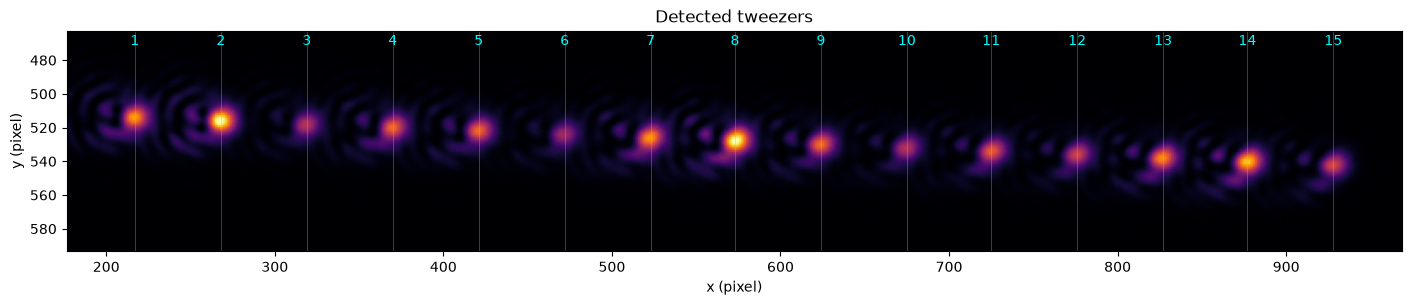

Initial centers: [217. 268. 319. 370. 421. 472. 523. 573. 624. 675. 725. 776. 827. 877.
 928.]


In [25]:
fig, axis = plt.subplots(figsize=(14, 6), constrained_layout=True)
axis.imshow(roi, origin="upper", cmap="inferno", aspect="equal",
               extent=(x_min - .5, x_max - .5, y_max - .5, y_min - .5))
for i, center in enumerate(centers_initial, 1):
    axis.axvline(center, color="cyan", alpha=.35, linewidth=.7)
    axis.text(center, y_min + 8, str(i), color="cyan", ha="center")
axis.set(xlabel="x (pixel)", ylabel="y (pixel)", title="Detected tweezers")
plt.show()
print("Initial centers:", centers_initial)

# 2D fit to find the center and axis

In [26]:
def core_gaussian(coords, background, amplitude, xc, yc, sx, sy):
    xx, yy = coords
    return (background + amplitude * np.exp(-0.5 * (((xx-xc)/sx)**2 + ((yy-yc)/sy)**2))).ravel()

core_parameters = []
core_patches = []            # measured patches, fitted images, and image-coordinate bounds
core_rmse = []
core_bound_flags = []
for id_spot, x_initial in enumerate(centers_initial, 1):
    x_guess = int(round(x_initial))
    search = image[y_min:y_max, max(0, x_guess-3):min(width, x_guess+4)]
    y_guess = y_min + int(np.argmax(gaussian_filter1d(search.sum(axis=1), 1)))
    xa, xb = max(0, x_guess-CORE_HALF_WIDTH), min(width, x_guess+CORE_HALF_WIDTH+1)  # the x limit of the patch
    ya, yb = max(0, y_guess-CORE_HALF_WIDTH), min(height, y_guess+CORE_HALF_WIDTH+1) # the y limit of the patch
    patch = image[ya:yb, xa:xb]
    yy, xx = np.mgrid[ya:yb, xa:xb]
    bg = np.percentile(patch, 10)
    guess = [bg, max(patch.max()-bg, 1), x_initial, y_guess, 4., 4.]
    lo = [-np.inf, 0, xa, ya, .1, .1]
    hi = [np.inf, np.inf, xb-1, yb-1, CORE_HALF_WIDTH, CORE_HALF_WIDTH]
    try:
        fitted_parameters, _ = curve_fit(core_gaussian, (xx, yy), patch.ravel(), p0=guess,
                           bounds=(lo, hi), x_scale="jac", max_nfev=3000)
    except (RuntimeError, ValueError) as exc:
        raise RuntimeError(f"Cannot locate spot {id_spot}; inspect detection and CORE_HALF_WIDTH.") from exc
    core_at_bound = bool(np.any(np.isclose(fitted_parameters, lo, atol=.02, rtol=0) | np.isclose(fitted_parameters, hi, atol=.02, rtol=0)))
    if core_at_bound:
        warnings.warn(f"Spot {id_spot}: local fit is near a bound; inspect the center overlay.")
    core_model = core_gaussian((xx, yy), *fitted_parameters).reshape(patch.shape)
    core_patches.append((patch.copy(), core_model, (xa, xb, ya, yb)))
    core_rmse.append(np.sqrt(np.mean((patch-core_model)**2)))
    core_bound_flags.append(core_at_bound)
    core_parameters.append(fitted_parameters)
core_parameters = np.asarray(core_parameters)

# the centers of the gaussian cores
centers_xy = core_parameters[:, 2:4]

array_origin = centers_xy.mean(axis=0)
_, _, vh = np.linalg.svd(centers_xy-array_origin, full_matrices=False)
xp_direction = vh[0]
if xp_direction[0] < 0:
    xp_direction = -xp_direction
yp_direction = np.array([-xp_direction[1], xp_direction[0]])
angle_deg = float(np.degrees(np.arctan2(xp_direction[1], xp_direction[0])))
projected_centers = (centers_xy-array_origin) @ xp_direction # project the points on the titled axis

spot_order = np.argsort(projected_centers)
initial_xp = projected_centers[spot_order]
transverse_offsets = (centers_xy-array_origin) @ yp_direction


print(f"Array angle: {angle_deg:.4f}° (positive = downward to the right)")
print(f"Center-line RMS deviation: {np.sqrt(np.mean(transverse_offsets**2)):.3f} pixels")

Array angle: 2.2768° (positive = downward to the right)
Center-line RMS deviation: 0.174 pixels


## Local 2D Gaussian fits
Each column shows one spot: measured patch, fitted Gaussian plus background, and data minus fit. All 15 spots are shown together in one figure with three rows. All data/fit panels share one intensity scale, and all residual panels share a symmetric scale. Cyan crosses mark fitted centers. Coordinates are original-image pixels (y increases downward).

The local model is axis-aligned in camera x/y, not along the tilted array. Its widths therefore differ in definition from the final along-array widths. The combined parameter table is shown at the end.

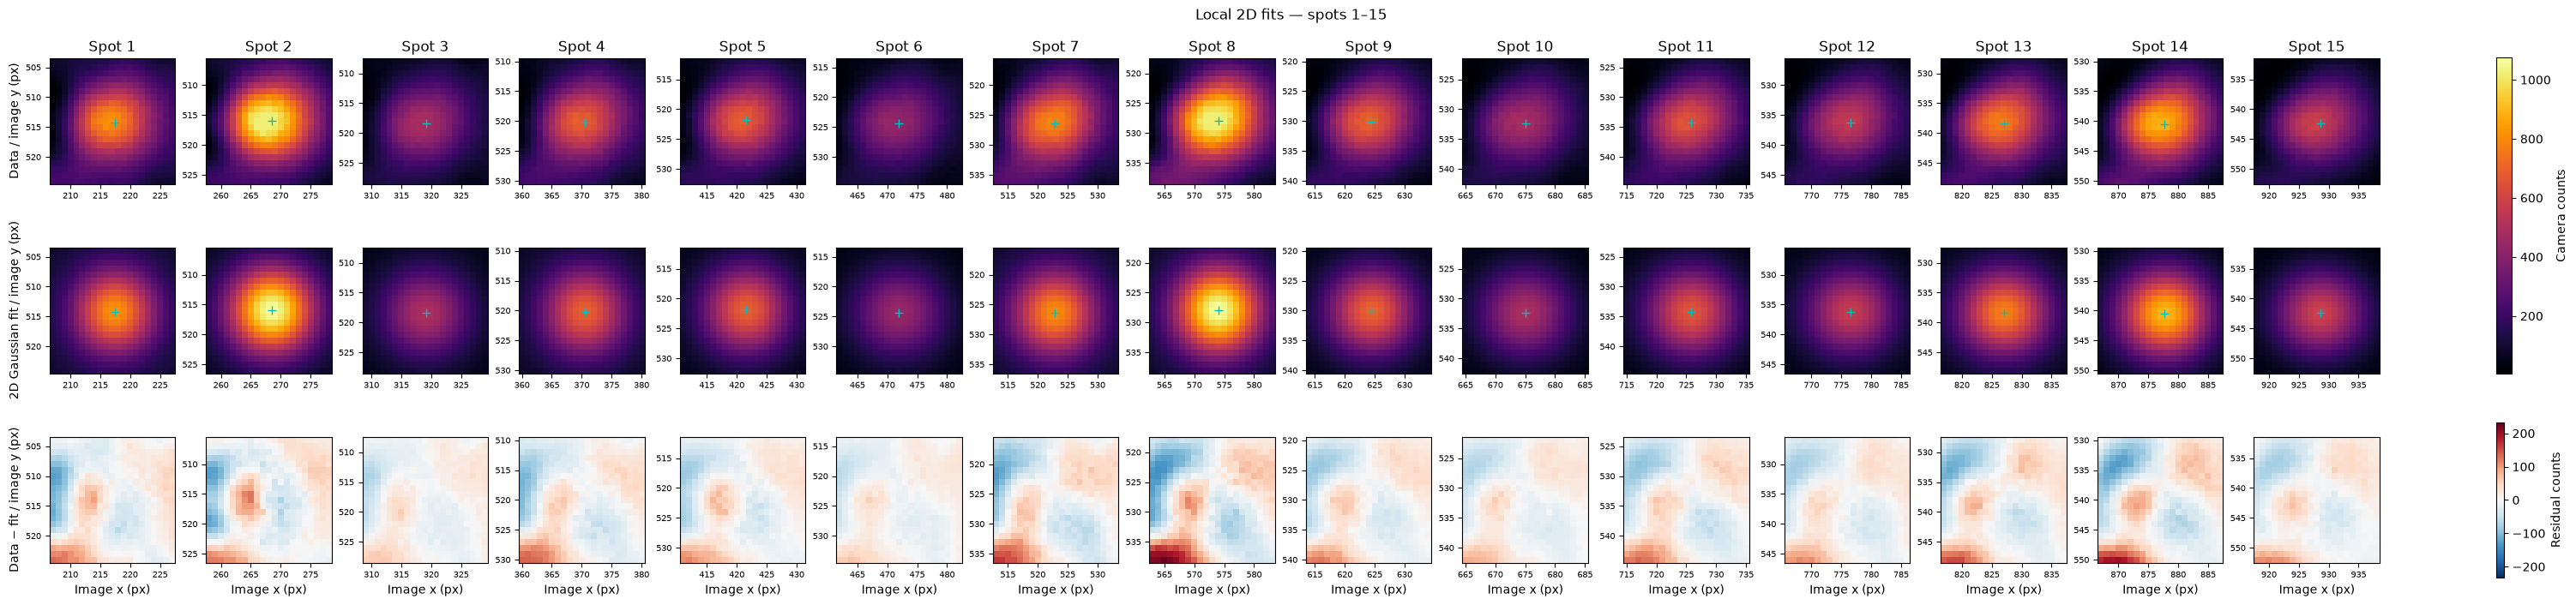

In [27]:
# Use the same left-to-right order as the tilted-axis results.
ordered_core = core_parameters[spot_order]
core_fwhm_factor = 2*np.sqrt(2*np.log(2))
core_results = pd.DataFrame({
    "spot": np.arange(1, N_SPOTS+1),
    "core_background_counts": ordered_core[:, 0],
    "core_amplitude_counts": ordered_core[:, 1],
    "core_x_center_px": ordered_core[:, 2],
    "core_y_center_px": ordered_core[:, 3],
    "core_sigma_x_px": ordered_core[:, 4],
    "core_sigma_y_px": ordered_core[:, 5],
    "core_sigma_x_um": ordered_core[:, 4]*PIXEL_SIZE_UM,
    "core_sigma_y_um": ordered_core[:, 5]*PIXEL_SIZE_UM,
    "core_fwhm_x_um": core_fwhm_factor*ordered_core[:, 4]*PIXEL_SIZE_UM,
    "core_fwhm_y_um": core_fwhm_factor*ordered_core[:, 5]*PIXEL_SIZE_UM,
    "core_rmse_counts": np.asarray(core_rmse)[spot_order],
    "core_near_fit_bound": np.asarray(core_bound_flags)[spot_order],
})
core_vmin = min(min(data.min(), model.min()) for data, model, _ in core_patches)
core_vmax = max(max(data.max(), model.max()) for data, model, _ in core_patches)
core_residual_limit = max(max(np.max(np.abs(data-model)) for data, model, _ in core_patches), 1e-12)
fig_cores = []
spots_per_figure = N_SPOTS  # keep every spot together in one figure
for start in range(0, N_SPOTS, spots_per_figure):
    stop = min(start+spots_per_figure, N_SPOTS)
    fig_core, axes = plt.subplots(3, stop-start, figsize=(max(12, 2*N_SPOTS), 7),
                                  squeeze=False, constrained_layout=True)
    for column, ordered_index in enumerate(range(start, stop)):
        original_index = spot_order[ordered_index]
        data, model, (xa, xb, ya, yb) = core_patches[original_index]
        extent = (xa-.5, xb-.5, yb-.5, ya-.5)
        for row, panel in enumerate([data, model, data-model]):
            ax = axes[row, column]
            if row < 2:
                intensity_artist = ax.imshow(panel, origin="upper", extent=extent,
                                             cmap="inferno", vmin=core_vmin, vmax=core_vmax)
                ax.plot(ordered_core[ordered_index, 2], ordered_core[ordered_index, 3], "c+", ms=7, mew=1)
            else:
                residual_artist = ax.imshow(panel, origin="upper", extent=extent, cmap="RdBu_r",
                                            vmin=-core_residual_limit, vmax=core_residual_limit)
                ax.set_xlabel("Image x (px)")
            ax.tick_params(labelsize=7)
        axes[0, column].set_title(f"Spot {ordered_index+1}")
    for row, label in enumerate(["Data", "2D Gaussian fit", "Data − fit"]):
        axes[row, 0].set_ylabel(label + " / image y (px)")
    fig_core.colorbar(intensity_artist, ax=axes[:2, :].ravel().tolist(), shrink=.85, label="Camera counts")
    fig_core.colorbar(residual_artist, ax=axes[2, :].ravel().tolist(), shrink=.85, label="Residual counts")
    fig_core.suptitle(f"Local 2D fits — spots {start+1}–{stop}")
    fig_cores.append(fig_core)
    plt.show()

# fit along the tilted array

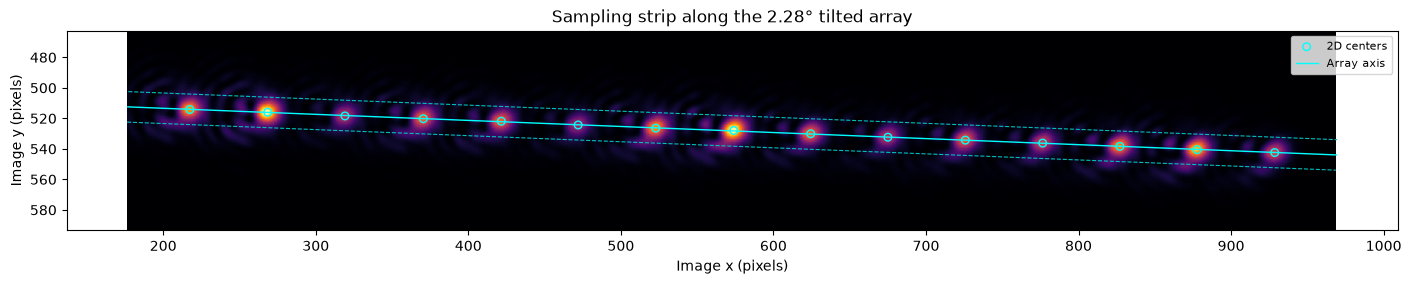

In [28]:
if not isinstance(STRIP_HALF_WIDTH, (int, np.integer)) or STRIP_HALF_WIDTH < 0:
    raise ValueError("STRIP_HALF_WIDTH must be a nonnegative integer.")
    
xp = np.arange(np.floor(initial_xp[0])-X_MARGIN, np.ceil(initial_xp[-1])+X_MARGIN+1)
yp = np.arange(-STRIP_HALF_WIDTH, STRIP_HALF_WIDTH+1)
xxp, yyp = np.meshgrid(xp, yp)

# Convert the rotated window coordinate back to the original axes and extract the data
sample_x = array_origin[0] + xxp*xp_direction[0] + yyp*yp_direction[0]
sample_y = array_origin[1] + xxp*xp_direction[1] + yyp*yp_direction[1]
if np.any((sample_x < 0) | (sample_x > width-1) | (sample_y < 0) | (sample_y > height-1)):
    raise ValueError("The strip leaves the image; reduce X_MARGIN or STRIP_HALF_WIDTH.")
strip = map_coordinates(image, [sample_y, sample_x], order=1, mode="constant", cval=np.nan)
along_profile = strip.mean(axis=0)

fig_axis, ax = plt.subplots(figsize=(14, 4), constrained_layout=True)
ax.imshow(roi, origin="upper", cmap="inferno",
          extent=(x_min-.5, x_max-.5, y_max-.5, y_min-.5))
ax.scatter(centers_xy[:, 0], centers_xy[:, 1], s=30, facecolors="none", edgecolors="cyan", label="2D centers")
ax.plot(array_origin[0]+xp*xp_direction[0], array_origin[1]+xp*xp_direction[1], color="cyan", lw=1, label="Array axis")
for edge in [-STRIP_HALF_WIDTH, STRIP_HALF_WIDTH]:
    ax.plot(array_origin[0]+xp*xp_direction[0]+edge*yp_direction[0],
            array_origin[1]+xp*xp_direction[1]+edge*yp_direction[1], "c--", lw=.8)
ax.set(xlabel="Image x (pixels)", ylabel="Image y (pixels)", title=f"Sampling strip along the {angle_deg:.2f}° tilted array")
ax.legend(fontsize=8)
plt.show()

### 3. Fit all 15 peaks along the array


In [29]:
xp_ref = xp.mean()
FWHM_FACTOR = 2*np.sqrt(2*np.log(2))

def gaussian_components(xp_values, triples):
    amplitude, center, sigma = np.asarray(triples).reshape(-1, 3).T
    return amplitude[:, None]*np.exp(-.5*((np.asarray(xp_values)[None, :]-center[:, None])/sigma[:, None])**2)

def tilted_model(xp_values, b0, b1, *triples):
    return b0 + b1*(xp_values-xp_ref) + gaussian_components(xp_values, triples).sum(axis=0)

background_guess = np.percentile(along_profile, 20)
amplitude_guess = np.maximum(np.interp(initial_xp, xp, along_profile)-background_guess, 1.)
sx, sy = core_parameters[spot_order, 4], core_parameters[spot_order, 5]
sigma_guess = 1/np.sqrt((xp_direction[0]/sx)**2 + (xp_direction[1]/sy)**2)
sigma_guess = np.clip(sigma_guess, SIGMA_BOUNDS[0]*1.1, SIGMA_BOUNDS[1]*.9)
p0 = np.r_[background_guess, 0., np.column_stack([amplitude_guess, initial_xp, sigma_guess]).ravel()]
lower = np.r_[-np.inf, -np.inf, np.column_stack([np.zeros(N_SPOTS), initial_xp-CORE_HALF_WIDTH, np.full(N_SPOTS, SIGMA_BOUNDS[0])]).ravel()]
upper = np.r_[np.inf, np.inf, np.column_stack([np.full(N_SPOTS, np.inf), initial_xp+CORE_HALF_WIDTH, np.full(N_SPOTS, SIGMA_BOUNDS[1])]).ravel()]
popt, pcov = curve_fit(tilted_model, xp, along_profile, p0=p0, bounds=(lower, upper),
                       x_scale="jac", max_nfev=5000)

parameters = popt[2:].reshape(N_SPOTS, 3)
fitted_centers = parameters[:, 1]
prediction = tilted_model(xp, *popt)
residual = along_profile-prediction
background = popt[0]+popt[1]*(xp-xp_ref)
r_squared = 1-np.sum(residual**2)/np.sum((along_profile-along_profile.mean())**2)
rmse = np.sqrt(np.mean(residual**2))
distance_um = (xp-fitted_centers[0])*PIXEL_SIZE_UM
center_distances_um = (fitted_centers-fitted_centers[0])*PIXEL_SIZE_UM
separations_um = np.diff(fitted_centers)*PIXEL_SIZE_UM
near_bound = (np.isclose(popt, lower, atol=.02, rtol=0) | np.isclose(popt, upper, atol=.02, rtol=0))[2:].reshape(-1, 3).any(axis=1)
if near_bound.any():
    warnings.warn("Some Gaussian parameters are near bounds. Inspect the fit before using the results.")
if not np.isfinite(pcov).all():
    warnings.warn("Covariance is not finite; parameter uncertainties are unreliable.")


results = pd.DataFrame({
    "spot": np.arange(1, N_SPOTS+1), "distance_from_first_um": center_distances_um,
    "xp_center_px": fitted_centers, "amplitude_mean_counts": parameters[:, 0],
    "sigma_along_px": parameters[:, 2], "sigma_along_um": parameters[:, 2]*PIXEL_SIZE_UM,
    "fwhm_along_um": FWHM_FACTOR*parameters[:, 2]*PIXEL_SIZE_UM,
    "radius_1e2_along_um": 2*parameters[:, 2]*PIXEL_SIZE_UM,
    "separation_to_next_um": np.r_[separations_um, np.nan], "near_fit_bound": near_bound
})
print(f"Scale: {PIXEL_SIZE_UM:g} µm/pixel; magnification M={MAGNIFICATION:g}. Confirm M for object-plane distances.")
print(f"Mean adjacent separation: {separations_um.mean():.3f} µm; spacing SD: {separations_um.std(ddof=1):.3f} µm")
print(f"First-to-last distance: {center_distances_um[-1]:.3f} µm")
print(f"Tilted-profile R²: {r_squared:.6f}; RMSE: {rmse:.3f} counts")

Scale: 0.138 µm/pixel; magnification M=25. Confirm M for object-plane distances.
Mean adjacent separation: 7.016 µm; spacing SD: 0.033 µm
First-to-last distance: 98.217 µm
Tilted-profile R²: 0.969917; RMSE: 25.211 counts


### 4. Inspect the fit and physical separations
The three panels show the tilted intensity fit, adjacent separations, and fitted amplitudes divided by their respective means. The third panel (`axes[2]`) compares the tilted 1D and local 2D ratios at the corresponding final 1D spot positions; the reference line at 1 marks the average. The shared x-axis is along-array distance from the first fitted spot. Adjust `STRIP_HALF_WIDTH` to check width/amplitude stability. Diffraction fringes are not described by the Gaussian model, and interpolation correlates neighboring samples, so the saved covariance is only an approximate uncertainty estimate.

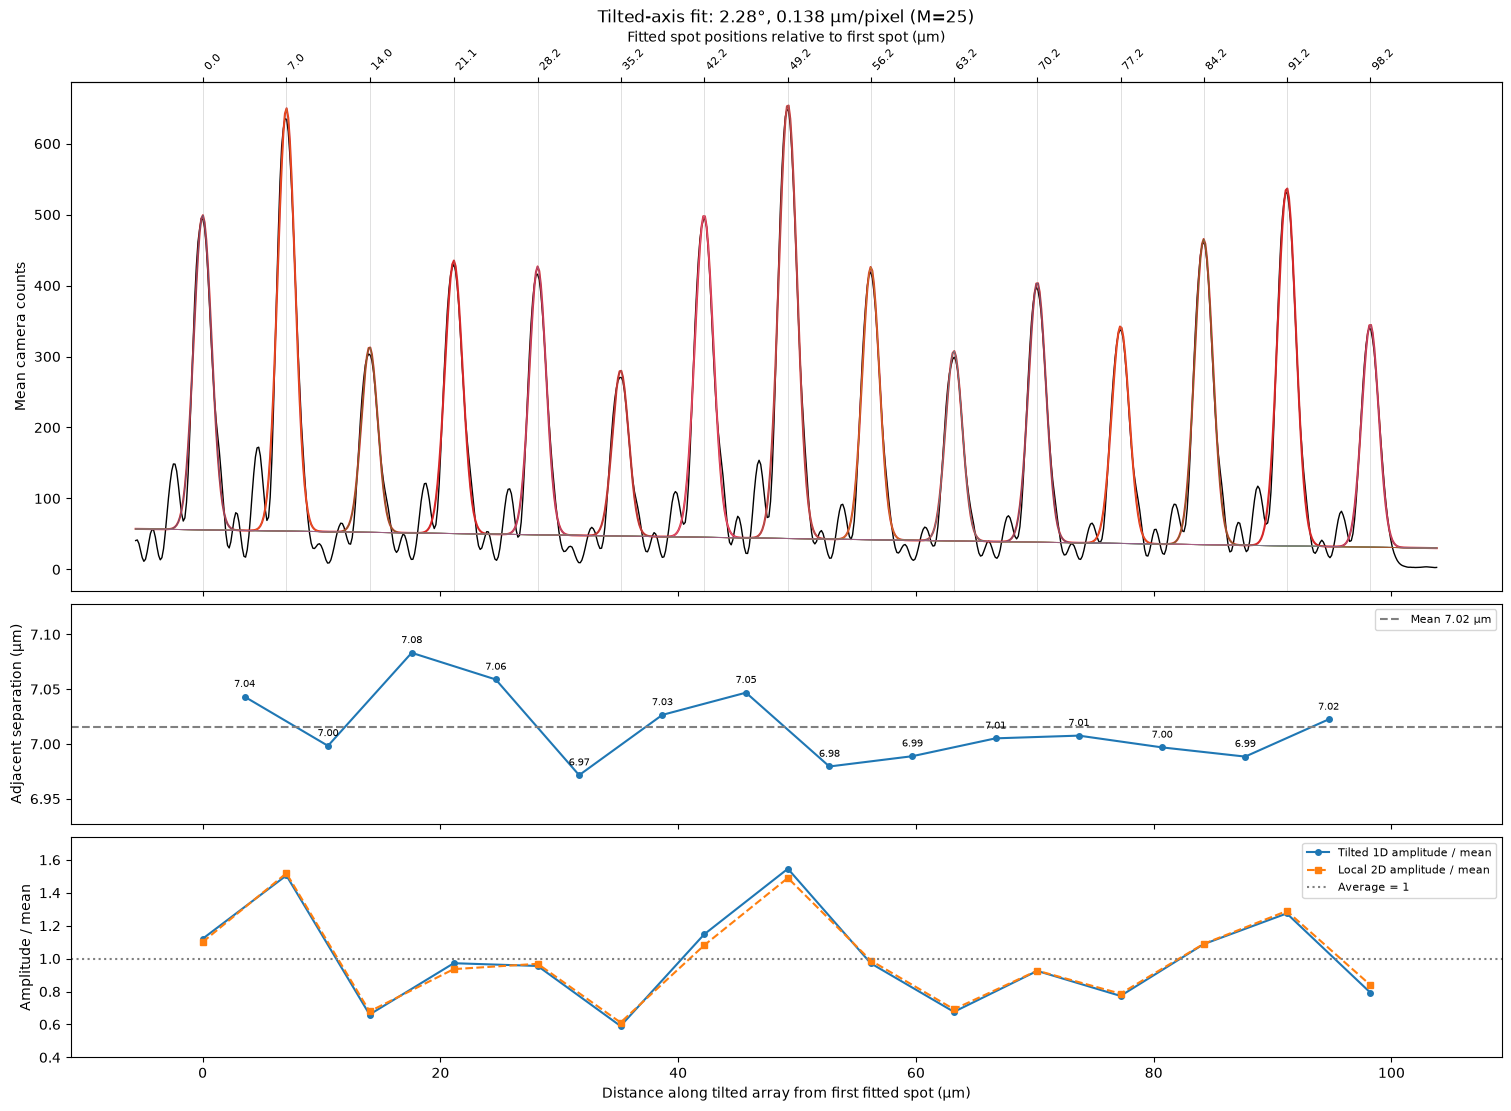

In [30]:
# Normalize amplitudes before plotting; the same ratios are saved below.
for table, amplitude_column, ratio_column in [
    (results, "amplitude_mean_counts", "amplitude_ratio_to_mean"),
    (core_results, "core_amplitude_counts", "core_amplitude_ratio_to_mean"),
]:
    amplitudes = table[amplitude_column].to_numpy(dtype=float)
    mean_amplitude = amplitudes.mean()
    if not np.isfinite(amplitudes).all() or not np.isfinite(mean_amplitude) or mean_amplitude <= 0:
        raise ValueError(f"Cannot normalize {amplitude_column}: amplitudes must be finite with a positive mean.")
    table[ratio_column] = amplitudes / mean_amplitude

fig_fit, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True,
                             gridspec_kw={"height_ratios": [3, 1.3, 1.3]}, constrained_layout=True)
axes[0].plot(distance_um, along_profile, color="black", lw=1, label="Tilted-strip data")
axes[0].plot(distance_um, prediction, color="tab:red", lw=1.5, label="15-Gaussian fit")
for i, component in enumerate(gaussian_components(xp, popt[2:])):
    axes[0].plot(distance_um, background+component, lw=.7, alpha=.6,
                 label="Individual Gaussians + background" if i == 0 else None)
for center_um in center_distances_um:
    axes[0].axvline(center_um, color="gray", lw=.5, alpha=.35)
top = axes[0].secondary_xaxis("top")
top.set_xticks(center_distances_um)
top.set_xticklabels([f"{v:.1f}" for v in center_distances_um], rotation=45, ha="left", fontsize=8)
top.set_xlabel("Fitted spot positions relative to first spot (µm)")
axes[0].set(ylabel="Mean camera counts", title=f"Tilted-axis fit: {angle_deg:.2f}°, {PIXEL_SIZE_UM:g} µm/pixel (M={MAGNIFICATION:g})")
# axes[0].legend(fontsize=8)
# axes[1].plot(distance_um, residual, lw=.8)
# axes[1].axhline(0, color="black", lw=.7)
# axes[1].set_ylabel("Data − fit")
midpoints_um = (center_distances_um[:-1]+center_distances_um[1:])/2
axes[1].plot(midpoints_um, separations_um, "o-", ms=4)
axes[1].axhline(separations_um.mean(), color="gray", ls="--", label=f"Mean {separations_um.mean():.2f} µm")
for midpoint, separation in zip(midpoints_um, separations_um):
    axes[1].annotate(f"{separation:.2f}", (midpoint, separation), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=7)
axes[1].margins(y=.4)
axes[1].set_ylabel("Adjacent separation (µm)")
axes[1].legend(fontsize=8)

# Third panel: peak amplitudes relative to each fit type's own mean.
axes[2].plot(center_distances_um, results["amplitude_ratio_to_mean"], "o-", ms=4, label="Tilted 1D amplitude / mean")
axes[2].plot(center_distances_um, core_results["core_amplitude_ratio_to_mean"], "s--", ms=4, label="Local 2D amplitude / mean")
axes[2].axhline(1.0, color="gray", ls=":", label="Average = 1")
axes[2].set(xlabel="Distance along tilted array from first fitted spot (µm)", ylabel="Amplitude / mean")
axes[2].margins(y=.2)
axes[2].legend(fontsize=8)
plt.show()

In [22]:
RF_power_calibration = 1/np.array(results["amplitude_ratio_to_mean"])
RF_power_calibration

array([1.17390339, 1.15377789, 0.73555567, 1.12615105, 1.04934377,
       0.76386118, 1.10833405, 1.30871756, 0.99397095, 0.86537262,
       1.03479027, 0.99421762, 0.95754189, 1.06023761, 1.01616564])

### 5. Save results
When `SAVE_RESULTS` is true, save the tilted-axis table, local 2D table, combined table, both sets of plots, fit covariance, and calibration metadata. The `_tilted_only` filename prefix is retained for compatibility with earlier exports. Rerunning overwrites these exports but never modifies the TIFF.

In [11]:
# Match the two fit stages by the common along-array spot numbering.
combined_results = results.merge(core_results, on="spot", how="left", validate="one_to_one")
if SAVE_RESULTS:
    import json
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    stem = image_path.stem + "_tilted_only"
    results.to_csv(OUTPUT_DIR / f"{stem}_gaussians.csv", index=False)
    core_results.to_csv(OUTPUT_DIR / f"{stem}_2d_gaussians.csv", index=False)
    combined_results.to_csv(OUTPUT_DIR / f"{stem}_combined_results.csv", index=False)
    pd.DataFrame({"xp_px": xp, "distance_um": distance_um, "measured_counts": along_profile,
                  "fitted_counts": prediction, "background_counts": background, "residual_counts": residual}).to_csv(
                      OUTPUT_DIR / f"{stem}_profile.csv", index=False)
    np.savez(OUTPUT_DIR / f"{stem}_fit.npz", parameters=popt, covariance=pcov,
             origin_xy=array_origin, direction_xy=xp_direction, xp_px=xp, xp_reference=xp_ref,
             local_core_parameters=core_parameters, initial_centers_xp=initial_xp)
    fig_axis.savefig(OUTPUT_DIR / f"{stem}_sampling_strip.png", dpi=180, bbox_inches="tight")
    fig_fit.savefig(OUTPUT_DIR / f"{stem}_fit_um.png", dpi=180, bbox_inches="tight")
    for page, fig_core in enumerate(fig_cores, 1):
        fig_core.savefig(OUTPUT_DIR / f"{stem}_2d_fits_{page:02d}.png", dpi=150, bbox_inches="tight")
    metadata = {"image": str(image_path.resolve()), "frame": 0, "n_spots": N_SPOTS,
                "camera_pixel_size_um": CAMERA_PIXEL_SIZE_UM, "magnification": MAGNIFICATION,
                "effective_pixel_size_um": PIXEL_SIZE_UM, "array_angle_deg": angle_deg,
                "array_origin_xy_px": array_origin.tolist(), "direction_xy": xp_direction.tolist(),
                "xp_px": xp.tolist(),
                "strip_half_width_px": STRIP_HALF_WIDTH, "core_half_width_px": CORE_HALF_WIDTH,
                "CORE_HALF_WIDTH_px": CORE_HALF_WIDTH, "sigma_bounds_px": list(SIGMA_BOUNDS),
                "xp_reference_px": float(xp_ref), "r_squared": float(r_squared), "rmse_counts": float(rmse),
                "mean_separation_um": float(separations_um.mean()),
                "mean_amplitude_1d_counts": float(results["amplitude_mean_counts"].mean()),
                "mean_amplitude_2d_counts": float(core_results["core_amplitude_counts"].mean()),
                "amplitude_ratio_definition": "fitted amplitude / arithmetic mean across all spots, separately for 1D and 2D fits",
                "parameter_order": "b0, b1, then (amplitude, xp_center_px, sigma_px) for each spot",
                "local_core_parameter_order": "background, amplitude, x_center, y_center, sigma_x, sigma_y",
                "weighting": "unweighted least squares", "profile": "bilinear interpolation, transverse mean"}
    (OUTPUT_DIR / f"{stem}_metadata.json").write_text(json.dumps(metadata, indent=2))
    print(f"Saved tilted-only results to {OUTPUT_DIR.resolve()}")

Saved tilted-only results to /home/xinyu-feng/MyApplications/AOD feedback/tweezer_gaussian_fit_results


## Final results — tilted 1D and local 2D fits
One row per spot, ordered along the array. Columns beginning with `core_` are from the local 2D fits; other columns describe the final tilted-axis fit. `core_x_center_px` and `core_y_center_px` are absolute camera-pixel coordinates. `distance_from_first_um` and `separation_to_next_um` come from the final 1D centers along the tilted axis. Local x/y widths are along camera axes, not the array axis.

`amplitude_ratio_to_mean` and `core_amplitude_ratio_to_mean` are each spot's fitted amplitude divided by the mean amplitude of its respective fit type. These dimensionless ratios average to 1: 1.10 means 10% above average, and 0.90 means 10% below average. They describe peak amplitudes above background, not integrated powers.

All micrometer values use `3.45 / MAGNIFICATION`. A missing separation for the last spot is expected. Scroll horizontally to see the full table. The combined CSV preserves unrounded values.

In [12]:
with pd.option_context("display.max_columns", None, "display.max_rows", N_SPOTS):
    display(combined_results.round(4))

,spot,distance_from_first_um,xp_center_px,amplitude_mean_counts,sigma_along_px,sigma_along_um,fwhm_along_um,radius_1e2_along_um,separation_to_next_um,near_fit_bound,amplitude_ratio_to_mean,core_background_counts,core_amplitude_counts,core_x_center_px,core_y_center_px,core_sigma_x_px,core_sigma_y_px,core_sigma_x_um,core_sigma_y_um,core_fwhm_x_um,core_fwhm_y_um,core_rmse_counts,core_near_fit_bound,core_amplitude_ratio_to_mean
0,1,0.0000,-356.4994,147.4329,5.0796,0.7010,1.6507,1.4020,7.0201,False,0.9619,16.4689,294.2974,191.3346,522.2411,5.2445,4.4301,0.7237,0.6113,1.7043,1.4396,11.2904,False,1.0175
1,2,7.0201,-305.6289,179.6758,5.4616,0.7537,1.7748,1.5074,7.1355,False,1.1723,26.2807,334.5005,242.2302,524.5673,5.2093,4.5341,0.7189,0.6257,1.6928,1.4734,14.3518,False,1.1565
2,3,14.1556,-253.9227,144.0430,5.2666,0.7268,1.7115,1.4536,6.9992,False,0.9398,24.4883,271.2849,293.9298,526.2322,5.1040,4.4517,0.7043,0.6143,1.6586,1.4467,12.0733,False,0.9379
3,4,21.1548,-203.2039,150.5234,5.1339,0.7085,1.6683,1.4170,6.9939,False,0.9821,15.1639,293.3966,344.5137,528.2576,5.2364,4.5485,0.7226,0.6277,1.7016,1.4781,12.1721,False,1.0144
4,5,28.1487,-152.5236,151.4526,5.3424,0.7372,1.7361,1.4745,7.0908,False,0.9882,22.0047,280.1393,395.1612,530.6371,5.2596,4.5870,0.7258,0.6330,1.7092,1.4906,13.2614,False,0.9686
5,6,35.2395,-101.1410,125.0549,5.2872,0.7296,1.7182,1.4593,7.0323,False,0.8159,22.0129,232.0527,446.5481,532.4428,5.2182,4.4919,0.7201,0.6199,1.6957,1.4597,11.7256,False,0.8023
6,7,42.2718,-50.1820,167.1961,5.3583,0.7394,1.7413,1.4789,6.9591,False,1.0909,24.3440,310.6465,497.3948,534.3213,5.2276,4.4290,0.7214,0.6112,1.6988,1.4393,13.3515,False,1.0740
7,8,49.2309,0.2461,197.6872,5.4494,0.7520,1.7709,1.5040,7.0266,False,1.2898,18.8258,366.7578,547.7974,536.6373,5.3937,4.6031,0.7443,0.6352,1.7528,1.4958,16.4295,False,1.2680
8,9,56.2575,51.1636,141.8455,5.3898,0.7438,1.7515,1.4876,7.0495,False,0.9255,22.0205,262.8539,598.6932,538.6516,5.2816,4.4588,0.7289,0.6153,1.7163,1.4489,14.6418,False,0.9088
9,10,63.3070,102.2470,126.8855,5.3404,0.7370,1.7355,1.4740,6.9850,False,0.8279,16.0346,239.6500,649.7488,540.5628,5.4043,4.5329,0.7458,0.6255,1.7562,1.4730,12.3908,False,0.8286
